# Конструктор: симуляция из блоков

Эксперимент собирается из функций `src/blocks/` и описывается данными
(`Recipe`), а не подклассом симулятора. Здесь два примера: (а) зависимость
T₂ᴱ от k_F·d для двух кубитов XXZ в ванне Кондо, как в демо R28, и (б)
один кубит сценария B, наблюдаемый точно и по конечному числу измерений.
Ноутбук ничего не пишет на диск и считается меньше минуты.

In [1]:
import math
import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = pathlib.Path().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import reproducibility
from src.blocks.recipe import Param, Recipe, block
from src.blocks.runner import run
from src.data.scenarios import build_configs

reproducibility.set_num_threads(1)

## (а) T₂ᴱ против k_F·d: Kondo-ванна у двух кубитов XXZ

Рецепт — это стадии конвейера. Расстояние между кубитами `kFd` — параметр,
который сэмплер выдаёт каждой траектории; `Param("kFd")` подставляется на
месте значения. `samplers.grid` обходит точки по порядку, поэтому
траектория `i` не зависит от числа траекторий.

In [2]:
kondo_recipe = Recipe(
    system=block("system.two_qubit", J=0.8, interaction="XXZ"),
    channels=(block("channels.kondo_bath", rho_J=0.1, kT=0.2, k_F=1.0,
                    dim=2, spacing=Param("kFd")),),
    initial=block("initial.random_pure"),
    observe=(block("observe.pauli_means"), block("observe.purity"),
             block("observe.coherence_l1")),
    target=block("target.energy_basis_crossing", threshold=1 / math.e),
    t_max=1200.0, dt=1.0,
    sampler=block("samplers.grid", kFd=[0.0, math.pi / 2, math.pi,
                                        3 * math.pi / 2, 2 * math.pi]),
)
runs = run(kondo_recipe, n_trajectories=5, seed=11)
table = pd.DataFrame({
    "kFd/pi": [r.params["kFd"] / math.pi for r in runs],
    "T2E": [r.target.time for r in runs],
    "censored": [r.target.censored for r in runs],
})
table

   kFd/pi         T2E  censored
0     0.0  468.407826     False
1     0.5  129.285801     False
2     1.0  108.355333     False
3     1.5   94.753012     False
4     2.0   81.295576     False

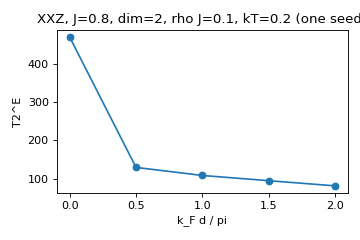

In [3]:
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.plot(table["kFd/pi"], table["T2E"], "o-")
ax.set_xlabel("k_F d / pi")
ax.set_ylabel("T2^E")
ax.set_title("XXZ, J=0.8, dim=2, rho J=0.1, kT=0.2 (one seed)")
fig.tight_layout()

Рецепт хешируется и сравнивается: смена одного блока — это новая строка, а
не новый класс. Тот же рецепт с дополнительным блоком
`channels.ou_modulation` даёт Kondo-ванну со стохастической скоростью, чего
подкласс симулятора сделать не мог.

In [4]:
modulated = Recipe(
    system=kondo_recipe.system,
    channels=kondo_recipe.channels + (
        block("channels.ou_modulation", s=0.3, tau=2.0),),
    initial=kondo_recipe.initial, observe=kondo_recipe.observe,
    target=kondo_recipe.target, t_max=kondo_recipe.t_max, dt=kondo_recipe.dt,
    sampler=kondo_recipe.sampler)
runs_ou = run(modulated, n_trajectories=5, seed=11)
pd.DataFrame({"kFd/pi": table["kFd/pi"], "T2E": table["T2E"],
              "T2E, OU": [r.target.time for r in runs_ou]})

   kFd/pi         T2E     T2E, OU
0     0.0  468.407826  478.535048
1     0.5  129.285801  123.097471
2     1.0  108.355333  107.339361
3     1.5   94.753012   94.586078
4     2.0   81.295576   71.167837

## (б) Сценарий B: точное наблюдение и конечное число измерений

Система и каналы одни и те же, меняется только блок наблюдения. Состояния
считаются одним и тем же потоком сидов (потоки стадий независимы), поэтому
шум измерений накладывается на одну и ту же траекторию. `finite_shots`
для каждого времени и каждого базиса разыгрывает `n_shots` исходов и
восстанавливает средние Паули; для одного кубита ещё и ρ̂, из которой
считаются чистота и когерентность.

In [5]:
config = build_configs(n_per_scenario=1, seed=0)["B"][0]
dissipator = config.dissipator


def scenario_b(observation):
    return Recipe(
        system=block("system.single_qubit", omega=config.omega),
        channels=(
            block("channels.jump", op_type=dissipator.operator_type.value,
                  gamma=1.0),
            block("channels.bernstein_profile",
                  coeffs=dissipator.gamma_coeffs)),
        initial=block("initial.random_pure"),
        observe=observation,
        target=block("target.coherence_crossing", threshold=1 / math.e),
        t_max=config.t_max, dt=config.dt)


exact = (block("observe.pauli_means"), block("observe.purity"),
         block("observe.coherence_l1"))
arms = {
    "exact": exact,
    "N=1000": (block("observe.finite_shots", n_shots=1000,
                     settings="tomography"),),
    "N=100": (block("observe.finite_shots", n_shots=100,
                    settings="tomography"),),
}
results = {name: run(scenario_b(obs), 1, seed=5)[0]
           for name, obs in arms.items()}
{name: r.target.time for name, r in results.items()}

{'exact': 9.024751841476617, 'N=1000': 9.024751841476617, 'N=100': 9.024751841476617}

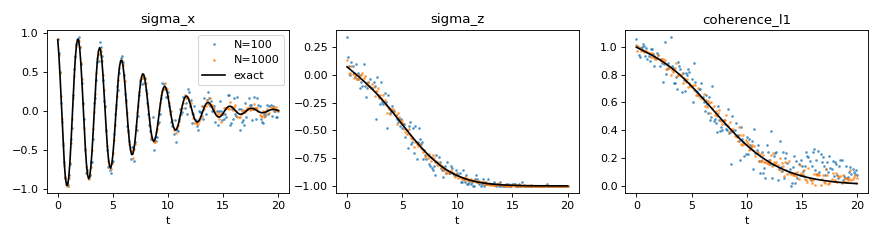

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharex=True)
for ax, name in zip(axes, ("sigma_x", "sigma_z", "coherence_l1")):
    times = results["exact"].observations.times
    for label, style in (("N=100", ".") , ("N=1000", ".")):
        ax.plot(times, results[label].observations.series[name], style,
                ms=3, alpha=0.6, label=label)
    ax.plot(times, results["exact"].observations.series[name], "k-",
            label="exact")
    ax.set_title(name)
    ax.set_xlabel("t")
axes[0].legend()
fig.tight_layout()

Цель считается по точному ρ(t), а не по оценкам, поэтому `T₂` у всех трёх
рядов один и тот же: меняется то, что видит модель, а не то, что
предсказывается. Шум убывает как 1/√N: разброс при N=100 втрое больше, чем
при N=1000.

In [7]:
exact_series = results["exact"].observations.series
pd.DataFrame({
    name: {key: float(np.std(
        results[name].observations.series[key] - exact_series[key]))
        for key in ("sigma_x", "sigma_y", "sigma_z", "purity",
                    "coherence_l1")}
    for name in ("N=100", "N=1000")}).round(4)

               N=100  N=1000
sigma_x       0.0896  0.0288
sigma_y       0.0832  0.0289
sigma_z       0.0561  0.0201
purity        0.0492  0.0143
coherence_l1  0.0835  0.0287